# Steering a soft robot through the brain ventricles with PPO (SOFA + Stable-Baselines3)

A tutorial on deep reinforcement learning for a surgical soft robot. A two-section pneumatic
continuum robot enters the skull at **Kocher's point**, leaves a rigid sheath at the frontal horn
of the right lateral ventricle, and must reach a target 80 mm along a planned path without leaving
the ventricle. The robot and the ventricle wall are simulated in **SOFA**. A **PPO** policy learns
to control insertion and bending.

**You will learn**

1. how patient data become an RL **environment** (SOFA scene + Gymnasium API),
2. how the **observation** and **action** spaces are designed (residual control on a nominal schedule),
3. how the **reward function** is built, term by term, and what each term does in a real episode,
4. what the **policy** is (actor-critic MLP) and how to query a trained one without the simulator,
5. how **PPO training** is set up and how to read its learning curves,
6. how two reward designs compare (**v1**: tip only, **v2**: tip + robot-body shape).

**Runs without SOFA.** Every result below is computed from files in `sofa_rl/results/` (training logs,
trained models, recorded episodes). Cells that call the simulator are guarded by `RUN_SOFA = False`;
see `sofa_rl/ENVIRONMENT.md` to build SOFA and retrain.

| Folder | Contents |
|---|---|
| `sofa_rl/rl/` | Gymnasium environment, PPO training, evaluation, policy-driven SOFA scene |
| `sofa_rl/cosserat_robot_01_from_matlab.py` | SOFA scene: robot, sheath, wall contact, pneumatic actuation |
| `sofa_rl/data/`, `poses/`, `walls/` | Patient 44 path, ventricle mesh, Kocher fiducials, design case, collision wall |
| `sofa_rl/results/` | Training logs, models (v1, v2), recorded rollouts and episodes |
| `sofa_rl/app.py` | Gradio demo |

## 0. Setup

In [1]:
# pip install -r sofa_rl/requirements.txt
import os
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
import torch                      # import before numpy/matplotlib (avoids an OpenMP clash on some Macs)
import ast, csv, glob, json, platform, struct, zipfile
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

ROOT = 'sofa_rl'
RES, DATA = f'{ROOT}/results', f'{ROOT}/data/patients_dataset'
RUN_SOFA = False                  # True: re-run SOFA (needs the build in sofa_rl/ENVIRONMENT.md)
torch.set_num_threads(1)

V1, V2, BASE, INK, MUTED, WALL = '#2a78d6', '#eb6834', '#8a8a86', '#0b0b0b', '#52514e', '#c9c8c3'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.edgecolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'lines.linewidth': 2})
import stable_baselines3, gymnasium
print('python', platform.python_version(), '| numpy', np.__version__, '| torch', torch.__version__,
      '| stable-baselines3', stable_baselines3.__version__, '| gymnasium', gymnasium.__version__)
print('reported runs: SOFA v26.06, Python 3.12.13, torch 2.7.1+cpu, SB3 2.6.0, gymnasium 1.1.1, Ubuntu 24.04')

def show(fn, name):
    # print the source of a function or method from a file without importing it (no SOFA needed)
    tree = ast.parse(open(fn).read())
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name == name:
            print(ast.get_source_segment(open(fn).read(), node)); return
    print('not found:', name)

python 3.13.13 | numpy 2.5.5 | torch 2.15.0 | stable-baselines3 2.6.0 | gymnasium 1.1.1
reported runs: SOFA v26.06, Python 3.12.13, torch 2.7.1+cpu, SB3 2.6.0, gymnasium 1.1.1, Ubuntu 24.04


## 1. The task and its data

The anatomy comes from an MRI-derived dataset of planned paths, ventricle surface meshes and 3D Slicer
fiducials (40 patients, left and right). This tutorial uses **patient 44, right ventricle** (shared with
the data owners' permission):

* **planned path** — centre path from the frontal-horn entry **F**; the goal is the path point at 80 mm
  (the robot's length);
* **ventricle mesh** — the wall: contacts, clearance, and the "left the lumen" failure test;
* **fiducials** — the coronal suture gives **Kocher's point K**; the rigid sheath is aimed from K to F.

The data are not a supervised training set. They define the **simulator**, and the agent generates its
own experience by interacting with it.

mesh 2500 triangles | path 33 points, 90.2 mm | goal at 80 mm
Kocher K -> entry F: 40.9 mm along the sheath axis, 0.29 mm off it


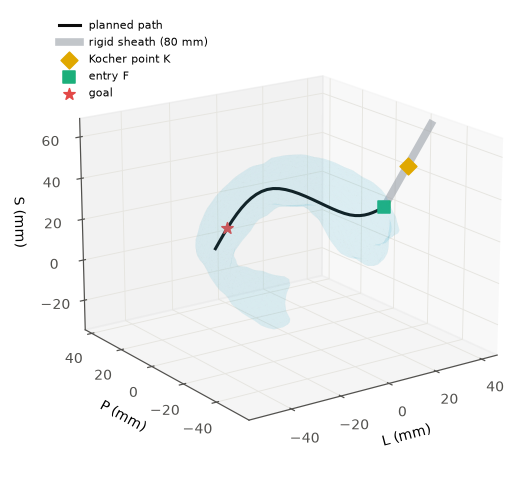

In [2]:
def read_stl(fn):
    b = open(fn, 'rb').read(); n = struct.unpack('<I', b[80:84])[0]
    a = np.frombuffer(b[84:84 + 50 * n], dtype=np.dtype([('n', '<f4', 3), ('v', '<f4', (3, 3)), ('a', '<u2')]))
    return a['v'].astype(float)                                    # [n, 3 vertices, xyz] mm

def read_fcsv(fn):
    return np.array([[float(v) for v in l.split(',')[1:4]] for l in open(fn) if l.strip() and not l.startswith('#')])

tris = read_stl(f'{DATA}/ventricles/patient44_right.stl')
path = np.loadtxt(f'{DATA}/paths/patient44_right.csv', delimiter=',')
suture = read_fcsv(f'{DATA}/kochers/patient44/OC_1.fcsv')
K = suture[-1]                                                     # lateral end of the suture line
ep = np.load(f'{RES}/episodes/episode_v2.npz')
goal = ep['goal']
roll = np.load(f'{RES}/rollouts/unity_v2.npz')                     # recorded rod shapes; sheath axis d, entry F
F, d = roll['F'], roll['d']
s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))]
print(f'mesh {len(tris)} triangles | path {len(path)} points, {s[-1]:.1f} mm | goal at 80 mm')
print(f'Kocher K -> entry F: {-(K - F) @ d:.1f} mm along the sheath axis, '
      f'{np.linalg.norm((K - F) - ((K - F) @ d) * d):.2f} mm off it')

fig = plt.figure(figsize=(7, 5.5)); ax = fig.add_subplot(projection='3d')
ax.add_collection3d(Poly3DCollection(tris, alpha=0.08, facecolor='#3fb6d8', edgecolor='none'))
ax.plot(*path.T, color=INK, lw=2, label='planned path')
ax.plot(*np.array([F - 80 * d, F]).T, color='#9aa0a8', lw=5, alpha=0.6, label='rigid sheath (80 mm)')
for p, m, c, l in [(K, 'D', '#e0a800', 'Kocher point K'), (F, 's', '#1baf7a', 'entry F'), (goal, '*', '#e34948', 'goal')]:
    ax.scatter(*p, marker=m, s=60, color=c, label=l, depthshade=False)
lo, hi = tris.reshape(-1, 3).min(0), tris.reshape(-1, 3).max(0)
c0, r0 = (lo + hi) / 2, (hi - lo).max() / 2 + 10
ax.set(xlim=(c0[0] - r0, c0[0] + r0), ylim=(c0[1] - r0, c0[1] + r0), zlim=(c0[2] - r0, c0[2] + r0),
       xlabel='L (mm)', ylabel='P (mm)', zlabel='S (mm)'); ax.view_init(18, -125)
ax.legend(loc='upper left', fontsize=7, frameon=False); plt.show()

## 2. The environment

**Simulator (SOFA v26.06).** The robot is a beam-FEM rod with 41 nodes, two bending sections (25 + 55 mm,
radius 3 mm). Nodes not yet inserted are held on the sheath axis behind F; inserting moves them out.
Bending comes from chamber pressures computed through a Yeoh hyperelastic actuator model. Wall contact is
solved as a linear complementarity problem (Gauss-Seidel, tolerance 1e-6). This tolerance is part of
the task: a coarser solver sends the robot into a different ventricle branch at a bifurcation.

### 2.1 Building the Gymnasium environment

No RL plugin for SOFA (such as SofaGym) is used. The SOFA scene is wrapped directly in a
[Gymnasium](https://gymnasium.farama.org/) environment, `VentricleNavEnv` in `sofa_rl/rl/ventricle_env.py`
(about 230 lines). Gymnasium is a standard interface: any class that subclasses `gym.Env` and provides the
members below can be trained by any Gymnasium-compatible library, here Stable-Baselines3. The library never
sees SOFA; it only calls `reset()` and `step()`.

| Member | Contract | What `VentricleNavEnv` does |
|---|---|---|
| `action_space` | shape and bounds of an action | `Box(-1, 1, (5,))`: insertion + 4 curvature residuals |
| `observation_space` | shape and bounds of an observation | `Box(-10, 10, (35,))`: tip, path, shape, wall, force (Section 3) |
| `reset(seed)` | start an episode, return `obs, info` | unload the old SOFA scene, build a new one with `createScene()`, settle for 2 steps |
| `step(action)` | advance once, return `obs, reward, terminated, truncated, info` | action → depth and chamber pressures → 10 SOFA steps → measure → reward |
| `close()` | release resources | unload the SOFA scene |

The interaction loop that PPO runs is:

```
obs, info = env.reset()
repeat:
    action = policy(obs)
    obs, reward, terminated, truncated, info = env.step(action)
    if terminated or truncated: obs, info = env.reset()
```

Inside `step()` the work splits into four helpers:

1. **`apply_action(a)`** turns the 5 numbers in [−1, 1] into an insertion depth and two curvature
   vectors, then into chamber pressures (Yeoh moment law), and writes them to the scene's controller.
2. **`Sofa.Simulation.animate()`** is called 10 times (10 × 10 ms = 0.1 s of simulated time).
3. **`_state()`** reads the result back from SOFA: node positions (`MechanicalObject.position`), contact
   forces from the constraint solver (`constraintForces`), distances to the wall mesh and to the planned path.
4. **`_obs()`** and the reward formula turn that state into the 35-value observation and a scalar reward.

`attach()` and `apply_action()` are separate methods so that the same code also runs inside the runSofa GUI:
`rl/policy_scene.py` lets runSofa build the scene, then calls `attach()` and `apply_action()` every 10 steps,
so a trained policy drives the robot with exactly the logic it was trained with.

In [3]:
env_src = f'{ROOT}/rl/ventricle_env.py'
src = open(env_src).read()
cls = next(n for n in ast.walk(ast.parse(src)) if isinstance(n, ast.ClassDef) and n.name == 'VentricleNavEnv')
print('class VentricleNavEnv(gym.Env):   # methods and their length')
for f in cls.body:
    if isinstance(f, ast.FunctionDef):
        print(f'  {f.end_lineno - f.lineno + 1:3d} lines   def {f.name}({", ".join(a.arg for a in f.args.args)})')

class VentricleNavEnv(gym.Env):   # methods and their length


   25 lines   def __init__(self, case, wall, sim_steps_per_action, max_steps, w_shape)
    3 lines   def _path_at(self, s_mm)
   10 lines   def _pressures(self)
   27 lines   def _state(self)
   10 lines   def _obs(self, st)
   12 lines   def reset(self, seed, options)
   18 lines   def attach(self, root)
   26 lines   def step(self, action)
   15 lines   def apply_action(self, action)
    4 lines   def _info(self, st)
    4 lines   def close(self)


**Constructor.** Imports SOFA and the scene module, loads the patient's wall mesh and planned path,
and declares the two spaces.

In [4]:
show(env_src, '__init__')

def __init__(self, case='design_patient44_right_r3_csf',
                 wall=os.path.join(SCENES, 'walls', 'patient44_right_entryhole.stl'),
                 sim_steps_per_action=10, max_steps=300, w_shape=0.0):
        self.w_shape = float(w_shape)
        os.environ.update(ROBOT_CASE=case, ROBOT_WALL=wall, ROBOT_RL='1')
        import Sofa.Core
        import Sofa.Simulation
        self.Sofa = Sofa
        self.scene = importlib.import_module('cosserat_robot_01_from_matlab')
        from ventricle_wall import read_stl, distance_to_mesh, inside
        self._dist, self._inside = distance_to_mesh, inside

        d = self.scene.DESIGN[case]
        self.wall_tri = read_stl(wall)                                          # mm
        full = os.path.join(os.path.dirname(os.path.dirname(d['ref_path_file'])), 'ventricles',
                            d['patient_path'] + '.stl')
        self.full_wall = read_stl(full) if os.path.exists(full) else self.wall_tri
        path = np.loadtxt(d[

**`reset()`** rebuilds the SOFA scene from scratch, so every episode starts with the robot retracted in
the sheath at Kocher's point. `attach()` binds the environment to the scene's controller and constraint
solver, finds the goal (the path point at the robot's full length) and zeroes the commands.

In [5]:
show(env_src, 'reset')
show(env_src, 'attach')

def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if self.root is not None:
            self.Sofa.Simulation.unload(self.root)
        self.root = self.Sofa.Core.Node('root')
        self.scene.createScene(self.root)
        self.Sofa.Simulation.initRoot(self.root)
        self.attach(self.root)
        for _ in range(2):
            self.Sofa.Simulation.animate(self.root, self.root.dt.value)
        st = self._state()
        return self._obs(st), self._info(st)
def attach(self, root):
        """Bind to an initialised scene (created here by reset(), or by runSofa for
        rl/policy_scene.py) and set the command state of a fresh episode."""
        self.root = root
        self.ctrl = self.root.SoftRobot.pneumatics
        self.solver = self.root.constraint_solver
        self.F = np.asarray(self.ctrl.rod['F']) * 1e3
        self.r_mm = max(sec['radius'] for sec in self.scene.SECTIONS) * 1e3
        self.goal = self._path_at(np.array([self.ctrl.rod[

**`step()`** applies the action, advances SOFA, measures and scores. `terminated` ends the episode on
full insertion (success bonus) or on leaving the ventricle (penalty); `truncated` is the step limit.

In [6]:
show(env_src, 'step')

def step(self, action):
        prev_depth = self.apply_action(action)

        t0 = time.perf_counter()
        for _ in range(self.sim_steps):
            self.Sofa.Simulation.animate(self.root, self.root.dt.value)
        self.sim_time += time.perf_counter() - t0
        self.n += 1

        st = self._state()
        ddepth_mm = (self.ctrl.cmd_depth - prev_depth) * 1e3
        r = (W_DEPTH * ddepth_mm - W_TIP * st['tip_err'] - self.w_shape * st['shape_err']
             - W_FORCE * st['force'] - W_TIME)
        terminated = False
        done = st['depth_mm'] >= st['L_mm'] - 1e-6
        success = done and st['goal_err'] <= GOAL_TOL_MM
        if not st['finite'] or st['outside'] > 0:
            r -= FAIL_PENALTY
            terminated = True
        elif done:
            r += SUCCESS_BONUS * np.exp(-st['goal_err'] / GOAL_SCALE_MM)
            terminated = True
        truncated = self.n >= self.max_steps
        info = self._info(st)
        info['success'] = bool(success)
     

**`_state()`** is where the simulator is read. Everything the observation and reward need is computed
here in millimetres.

In [7]:
show(env_src, '_state')

def _state(self):
        rod = self.ctrl.rod
        x = np.asarray(self.ctrl.dofs.position.value)
        L_mm = rod['s'][-1] * 1e3
        depth_mm = self.ctrl.depth * 1e3
        s_out = rod['s'] * 1e3 - (L_mm - depth_mm)          # arc length past F (<= 0: in sheath)
        free = s_out > 1e-6
        pts = x[:, :3] * 1e3
        tip = pts[-1]
        R = self.scene.quat_to_rotm(x[-1, 3:])
        st = dict(x=x, pts=pts, free=free, s_out=s_out, tip=tip, tangent=R[:, 0],
                  depth_mm=depth_mm, L_mm=L_mm)
        if free.any():
            dist = self._dist(pts[free], self.wall_tri)
            st['clear_tip'] = dist[-1] - self.r_mm
            st['clear_min'] = dist.min() - self.r_mm
            p_ref = self._path_at(s_out[free])
            st['shape_err'] = np.linalg.norm(pts[free] - p_ref, axis=1).mean()
            st['outside'] = int(np.sum(~self._inside(pts[free], self.full_wall)))
        else:
            st.update(clear_tip=10.0, clear_min=10.0, shape_err=0.

**The spaces are plain Gymnasium objects.** They define what the policy network sees and outputs:
the network has 35 inputs and outputs the mean of a 5-D Gaussian whose samples are clipped to the action box.

In [8]:
from gymnasium import spaces
action_space = spaces.Box(-1.0, 1.0, (5,), np.float32)
observation_space = spaces.Box(-10.0, 10.0, (35,), np.float32)
action_space.seed(0)
print('action space     ', action_space)
print('observation space', observation_space)
print('random action    ', np.round(action_space.sample(), 3))
print('recorded v2 obs in bounds:', all(observation_space.contains(o.astype(np.float32)) for o in ep['obs']))

action space      Box(-1.0, 1.0, (5,), float32)
observation space Box(-10.0, 10.0, (35,), float32)
random action     [ 0.274 -0.46  -0.918 -0.967  0.627]
recorded v2 obs in bounds: True


**The contract in action, without SOFA.** To show that Stable-Baselines3 depends only on the Gymnasium
interface, the cell below defines `ReplayEnv`: an environment with the same spaces that replays the
recorded v2 episode instead of simulating. Gymnasium's own `check_env` validates it, SB3 wraps it in a
vectorised environment, and the trained v2 policy runs on it. With SOFA installed, replacing `ReplayEnv`
by `VentricleNavEnv` is the only change needed (`rl/check_env.py` runs the same check on the real environment).

In [9]:
import gymnasium as gym
from gymnasium.utils.env_checker import check_env
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv

class ReplayEnv(gym.Env):
    # same interface as VentricleNavEnv; returns the recorded observations and rewards instead of simulating
    def __init__(self, episode):
        self.e = episode
        self.action_space = spaces.Box(-1.0, 1.0, (5,), np.float32)
        self.observation_space = spaces.Box(-10.0, 10.0, (35,), np.float32)
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.t = 0
        return self.e['obs'][0].astype(np.float32), {}
    def step(self, action):
        self.t += 1
        T = len(self.e['action'])
        obs = self.e['obs'][self.t].astype(np.float32)
        info = {'goal_err_mm': float(self.e['goal_err_mm'][self.t - 1])}
        return obs, float(self.e['reward'][self.t - 1]), self.t >= T, False, info

check_env(ReplayEnv(ep), skip_render_check=True)          # raises if the API is not respected
print('gymnasium check_env: passed')

venv = DummyVecEnv([lambda: ReplayEnv(ep)])                # SB3 vectorised env (training used SubprocVecEnv x 5)
policy = PPO.load(f'{RES}/ppo_p44_server_v2_shape/final_model.zip', device='cpu')
obs, ret, n = venv.reset(), 0.0, 0
while True:
    act, _ = policy.predict(obs, deterministic=True)
    obs, r, done, info = venv.step(act)
    ret, n = ret + r[0], n + 1
    if done[0]:
        break
print(f'{n} steps through the SB3 API, return {ret:.2f} (recorded {ep["reward"].sum():.2f}), '
      f'final goal error {info[0]["goal_err_mm"]:.2f} mm')

gymnasium check_env: passed


80 steps through the SB3 API, return 22.16 (recorded 22.16), final goal error 0.67 mm


In [10]:
if RUN_SOFA:     # needs the SOFA build; run from sofa_rl/ with rl/run.sh (macOS) or rl/run_server.sh (Linux)
    import subprocess
    subprocess.run('rl/run_server.sh rl/check_env.py', shell=True, cwd=ROOT, check=True)

## 3. Observation space (35 values)

| Index | Content | Scale |
|---|---|---|
| 0–2 | tip − goal | ÷ 50 mm |
| 3–5 | tip − path point at the current insertion depth | ÷ 50 mm |
| 6–8 | tip direction (unit vector) | – |
| 9 | inserted depth / robot length | 0–1 |
| 10–13 | commanded curvatures (2 sections × 2 bending planes) | ÷ κ<sub>max</sub> |
| 14–31 | 6 robot nodes relative to F | ÷ 50 mm |
| 32–33 | wall clearance at the tip and minimum along the robot | ÷ 10 mm |
| 34 | total wall-contact force | ÷ 0.05 |

The scales keep every input near unit size. The policy also sees its own curvature commands (10–13),
because the action changes them incrementally.

def _obs(self, st):
        x, free, pts = st['x'], st['free'], st['pts']
        F = self.F
        idx = np.linspace(0, len(pts) - 1, N_SHAPE_POINTS).astype(int)
        shape = (pts[idx] - F) / 50.0
        ref_now = self._path_at(np.array([max(st['depth_mm'], 0.0)]))[0]
        o = np.concatenate([(st['tip'] - self.goal) / 50.0, (st['tip'] - ref_now) / 50.0, st['tangent'],
                            [st['depth_mm'] / st['L_mm']], np.ravel(self.kappa) / KAPPA_MAX, shape.ravel(),
                            [st['clear_tip'] / 10.0, st['clear_min'] / 10.0, st['force'] / 0.05]])
        return np.clip(np.nan_to_num(o, nan=0.0, posinf=10.0, neginf=-10.0), -10, 10).astype(np.float32)


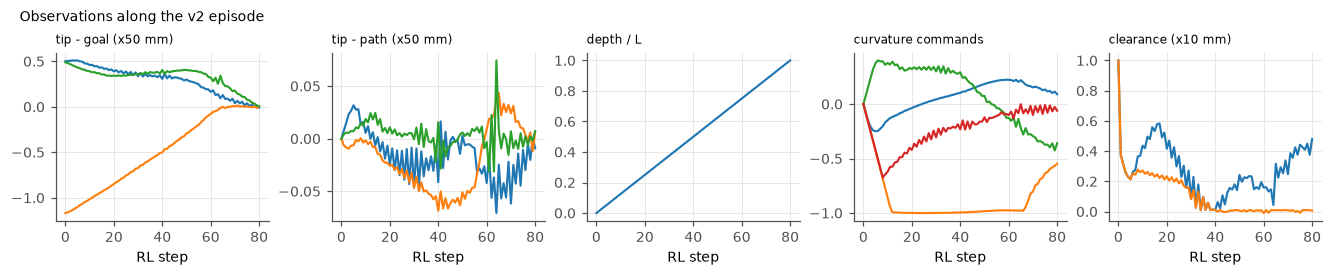

In [11]:
show(env_src, '_obs')
obs = ep['obs']
groups = {'tip - goal (x50 mm)': slice(0, 3), 'tip - path (x50 mm)': slice(3, 6), 'depth / L': slice(9, 10),
          'curvature commands': slice(10, 14), 'clearance (x10 mm)': slice(32, 34)}
fig, axs = plt.subplots(1, len(groups), figsize=(12, 2.4), constrained_layout=True)
for ax, (t, sl) in zip(axs, groups.items()):
    ax.plot(obs[:, sl], lw=1.4); ax.set_title(t, fontsize=8, loc='left'); ax.set_xlabel('RL step')
fig.suptitle('Observations along the v2 episode', fontsize=9, x=0.01, ha='left'); plt.show()

## 4. Action space (5 values in [−1, 1])

* **a₀: insertion** — 0.5·(1 + a₀) mm per step: forward only, 0–1 mm.
* **a₁…a₄: curvature residuals** — each step adds a₁…a₄ × 0.01 1/mm to a residual on the four curvature
  components (section 1 and 2, two bending planes each).

The commanded curvature is **depth-scaled nominal schedule + accumulated residual**, clipped to
κ<sub>max</sub> = 0.12 1/mm:

$$\kappa_t = \frac{d_t}{L}\,\kappa_{\text{fit}} + \sum_{\tau \le t} 0.01\,a_{1..4,\tau}$$

This is **residual RL**. The nominal schedule κ<sub>fit</sub> (fitted to the planned path) already gives the
gross shape, so the policy only learns corrections. On its own, the schedule ends in the wrong ventricle
branch, 45 mm from the goal.

def apply_action(self, action):
        """Turn a policy action into the insertion depth and chamber pressures the scene
        controller applies over the next sim_steps; returns the previous depth [m]."""
        a = np.clip(np.asarray(action, float), -1, 1)
        L = self.ctrl.rod['s'][-1]
        prev_depth = self.ctrl.cmd_depth
        self.ctrl.cmd_depth = float(min(prev_depth + (0.5 + 0.5 * a[0]) * DEPTH_STEP_MM * 1e-3, L))
        self.residual = np.clip(self.residual + a[1:].reshape(2, 2) * DKAPPA, -KAPPA_MAX, KAPPA_MAX)
        self.kappa = self.ctrl.cmd_depth / L * self.k_fit + self.residual
        for j in range(2):
            m = np.linalg.norm(self.kappa[j])
            if m > KAPPA_MAX:
                self.kappa[j] *= KAPPA_MAX / m
        self.ctrl.cmd_pressures = self._pressures()
        return prev_depth


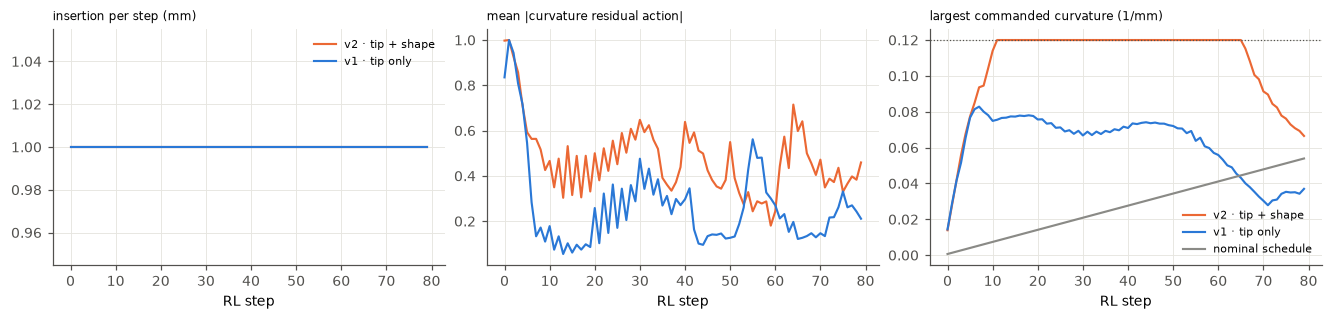

In [12]:
show(env_src, 'apply_action')
episodes = {'v2 · tip + shape': (np.load(f'{RES}/episodes/episode_v2.npz'), V2),
            'v1 · tip only': (np.load(f'{RES}/episodes/episode_v1.npz'), V1),
            'nominal schedule': (np.load(f'{RES}/episodes/episode_baseline.npz'), BASE)}
fig, axs = plt.subplots(1, 3, figsize=(12, 2.8), constrained_layout=True)
for name, (e, col) in list(episodes.items())[:2]:
    axs[0].plot(0.5 * (1 + e['action'][:, 0]), color=col, lw=1.4, label=name)
    axs[1].plot(np.abs(e['action'][:, 1:]).mean(1), color=col, lw=1.4, label=name)
for name, (e, col) in episodes.items():
    axs[2].plot(np.linalg.norm(e['kappa'], axis=2).max(1) / 1e3, color=col, lw=1.4, label=name)
for a, t in zip(axs, ['insertion per step (mm)', 'mean |curvature residual action|', 'largest commanded curvature (1/mm)']):
    a.set_title(t, fontsize=8, loc='left'); a.set_xlabel('RL step')
axs[2].axhline(0.12, color=MUTED, lw=0.8, ls=':')
axs[0].legend(frameon=False, fontsize=7); axs[2].legend(frameon=False, fontsize=7); plt.show()

Both policies always insert the full 1 mm per step (the v2 line is hidden under v1), so all the control
goes into the curvature residuals. They use them very differently: **v2 drives a section to the
curvature limit (0.12 1/mm) for most of the insertion**, bending harder to keep the body on the path,
while v1 stays near 0.07 1/mm. The nominal schedule only scales its fitted curvature with depth.

## 5. Reward function

$$r_t = \underbrace{0.2\,\Delta d_t}_{\text{progress}}
 \;\underbrace{-\,0.002\,e^{\text{tip}}_t}_{\text{tip tracking}}
 \;\underbrace{-\,w_{\text{shape}}\,e^{\text{shape}}_t}_{\text{body on path (v2)}}
 \;\underbrace{-\,20\,f_t}_{\text{contact}}
 \;\underbrace{-\,0.01}_{\text{time}}
 \;+\;\underbrace{10\,e^{-e^{\text{goal}}/10}}_{\text{at full insertion}}
 \;\underbrace{-\,10}_{\text{left the lumen}}$$

* $\Delta d_t$ is the inserted millimetres. Completing the insertion is always worth more than stalling.
* $e^{\text{tip}}_t$ is the tip distance to the path point at the same depth (a moving reference).
* $e^{\text{shape}}_t$ is the mean distance of all inserted nodes to the path at equal arc length.
  **v1: $w_{\text{shape}} = 0$; v2: $w_{\text{shape}} = 0.01$ 1/mm.**
* $f_t$ is the total wall-contact force. The terminal bonus decays smoothly with goal error.
  Success means goal error ≤ 3 mm; it is a metric, not a reward step.

In [13]:
show(env_src, 'step')

def step(self, action):
        prev_depth = self.apply_action(action)

        t0 = time.perf_counter()
        for _ in range(self.sim_steps):
            self.Sofa.Simulation.animate(self.root, self.root.dt.value)
        self.sim_time += time.perf_counter() - t0
        self.n += 1

        st = self._state()
        ddepth_mm = (self.ctrl.cmd_depth - prev_depth) * 1e3
        r = (W_DEPTH * ddepth_mm - W_TIP * st['tip_err'] - self.w_shape * st['shape_err']
             - W_FORCE * st['force'] - W_TIME)
        terminated = False
        done = st['depth_mm'] >= st['L_mm'] - 1e-6
        success = done and st['goal_err'] <= GOAL_TOL_MM
        if not st['finite'] or st['outside'] > 0:
            r -= FAIL_PENALTY
            terminated = True
        elif done:
            r += SUCCESS_BONUS * np.exp(-st['goal_err'] / GOAL_SCALE_MM)
            terminated = True
        truncated = self.n >= self.max_steps
        info = self._info(st)
        info['success'] = bool(success)
     

episode                progress tip tracking   body shape      contact         time     terminal    return  goal err
v2 · tip + shape          16.00        -0.34        -1.90        -0.14        -0.80         9.35     22.16     0.67 mm
v1 · tip only             16.00        -0.32         0.00        -0.23        -0.80         8.86     23.51     1.21 mm
nominal schedule          16.00        -4.60         0.00        -2.64        -0.80         0.11      8.07    45.35 mm

(each episode is scored with the reward it was trained with: w_shape = 0.01 for v2, 0 otherwise)


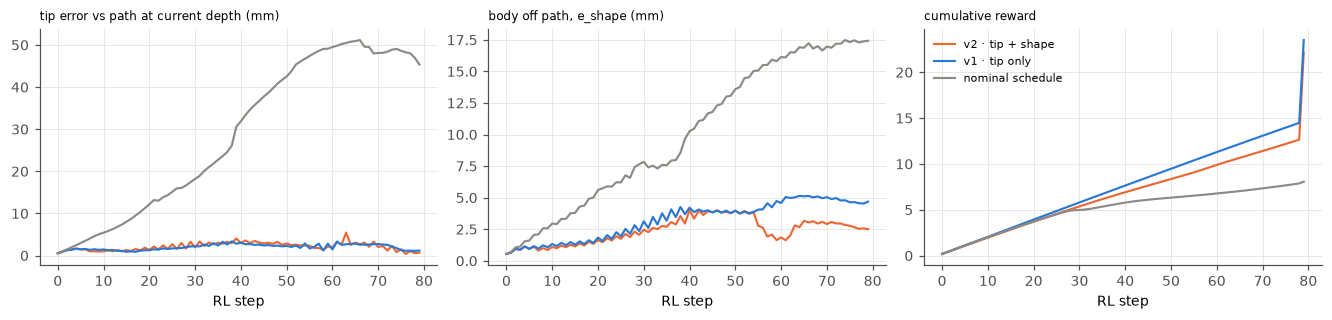

In [14]:
terms = ['r_depth', 'r_tip', 'r_shape', 'r_force', 'r_time', 'r_terminal']
labels = ['progress', 'tip tracking', 'body shape', 'contact', 'time', 'terminal']
print(f'{"episode":<18}' + ''.join(f'{l:>13}' for l in labels) + f'{"return":>10}{"goal err":>10}')
for name, (e, _) in episodes.items():
    print(f'{name:<18}' + ''.join(f'{e[t].sum():13.2f}' for t in terms) + f'{e["reward"].sum():10.2f}{e["goal_err_mm"][-1]:9.2f} mm')
print('\n(each episode is scored with the reward it was trained with: w_shape = 0.01 for v2, 0 otherwise)')

fig, axs = plt.subplots(1, 3, figsize=(12, 2.8), constrained_layout=True)
for name, (e, col) in episodes.items():
    axs[0].plot(e['tip_err_mm'], color=col, lw=1.4, label=name)
    axs[1].plot(e['shape_err_mm'], color=col, lw=1.4, label=name)
    axs[2].plot(np.cumsum(e['reward']), color=col, lw=1.4, label=name)
for a, t in zip(axs, ['tip error vs path at current depth (mm)', 'body off path, e_shape (mm)', 'cumulative reward']):
    a.set_title(t, fontsize=8, loc='left'); a.set_xlabel('RL step')
axs[2].legend(frameon=False, fontsize=7); plt.show()

The nominal schedule collects the same progress reward as the policies but almost no terminal bonus,
because it ends 45 mm from the goal. It also pays more than ten times the contact penalty, because it
presses into the wall of the wrong branch. v1 and v2 track the tip about equally well; only v2 keeps the
**body** near the path, because only v2 pays for it.

## 6. The policy

PPO uses an **actor-critic**. The **actor** maps the 35-value observation to the mean of a Gaussian over
the 5 actions (state-independent log-std). The **critic** estimates the state value V(s) used for
advantages. Both are 2 × 128 tanh MLPs. Below, the trained v2 model is loaded from its zip file and
queried on the recorded observations. It reproduces the recorded actions to float precision, so you
can analyse the policy without SOFA. (v1's return, 23.5, is higher than v2's, 22.2, only because v2 is also
charged for its body shape: returns from different reward functions are not comparable.)

ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=35, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=35, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=128, out_features=5, bias=True)
  (value_net): Linear(in_features=128, out_features=1, bias=True)
)
parameters: 43019 | action std: [0.63  0.845 0.769 0.659 0.723]
max |predicted - recorded action| over 80 steps: 5.36e-07


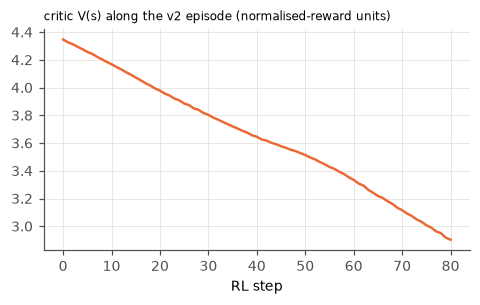

In [15]:
from stable_baselines3 import PPO
models = {'v2': PPO.load(f'{RES}/ppo_p44_server_v2_shape/final_model.zip', device='cpu'),
          'v1': PPO.load(f'{RES}/ppo_p44_server_v1/model_190k.zip', device='cpu')}
m = models['v2']
print(m.policy)
print('parameters:', sum(p.numel() for p in m.policy.parameters()),
      '| action std:', np.round(m.policy.log_std.exp().detach().numpy(), 3))

e = episodes['v2 · tip + shape'][0]
pred, _ = m.predict(e['obs'][:-1], deterministic=True)
print(f'max |predicted - recorded action| over {len(pred)} steps: {np.abs(pred - e["action"]).max():.2e}')

with torch.no_grad():
    values = m.policy.predict_values(torch.as_tensor(e['obs'], dtype=torch.float32)).numpy().ravel()
plt.figure(figsize=(5, 2.6)); plt.plot(values, color=V2, lw=1.6)
plt.title('critic V(s) along the v2 episode (normalised-reward units)', fontsize=8, loc='left'); plt.xlabel('RL step'); plt.show()

## 7. Training with PPO

PPO collects rollouts with the current policy, then takes several gradient steps on the **clipped
surrogate objective**

$$L(\theta) = \mathbb{E}_t\big[\min\big(\rho_t A_t,\ \mathrm{clip}(\rho_t, 1-\epsilon, 1+\epsilon)\,A_t\big)\big],
\quad \rho_t = \frac{\pi_\theta(a_t|s_t)}{\pi_{\theta_\text{old}}(a_t|s_t)}$$

plus a value-function loss. The clip keeps each update close to the policy that collected the data.
Advantages $A_t$ come from generalised advantage estimation (GAE). Rewards are normalised online
(VecNormalize); observations are not normalised, since they are already scaled.

**Training system.** 5 SOFA simulators run in parallel processes (`SubprocVecEnv`), about 60 steps/s on 6
CPU cores, so 200k steps take about 1 h. Each episode reset rebuilds the SOFA scene, and the worker
processes leak memory: the first run was killed by the out-of-memory killer at 198.4k steps. Training
now runs one rollout per `learn()` call and respawns the workers when one exceeds 1.5 GB, keeping the
policy, optimiser and normaliser, so no steps are lost. `rl/train_supervised.sh` resumes from the newest
checkpoint after a crash.

In [16]:
hp = {k: getattr(m, k) for k in ['n_steps', 'batch_size', 'n_epochs', 'learning_rate', 'gamma', 'gae_lambda', 'ent_coef', 'vf_coef', 'max_grad_norm']}
# clip_range / lr_schedule are pickled functions in the zip: calling them under a different Python version than
# the one that saved the model (3.12) can crash the interpreter, so the clip value is read from train_ppo.py
clip = [l for l in open(f'{ROOT}/rl/train_ppo.py') if 'clip_range=' in l][0].split('clip_range=')[1].split(',')[0]
hp.update(clip_range=float(clip), n_envs=5, rollout_size=5 * m.n_steps, net_arch='[128, 128] actor and critic, tanh')
for k, v in hp.items():
    print(f'{k:<15} {v}')
cmds = {'v1': 'rl/run_server.sh rl/train_ppo.py --name ppo_p44_server_v1 --steps 200000 --envs 5 --n-steps 256 --ckpt 10000 --max-episode-steps 250',
        'v2': 'rl/train_supervised.sh ppo_p44_server_v2_shape 200000 --envs 5 --n-steps 256 --ckpt 10000 --max-episode-steps 250 --w-shape 0.01'}
if RUN_SOFA:
    import subprocess
    for c in cmds.values():
        subprocess.run(c, shell=True, cwd=ROOT, check=True)          # ~1 h each on 6 cores

n_steps         256
batch_size      256
n_epochs        10
learning_rate   0.0003
gamma           0.99
gae_lambda      0.95
ent_coef        0.0
vf_coef         0.5
max_grad_norm   0.5
clip_range      0.2
n_envs          5
rollout_size    1280
net_arch        [128, 128] actor and critic, tanh


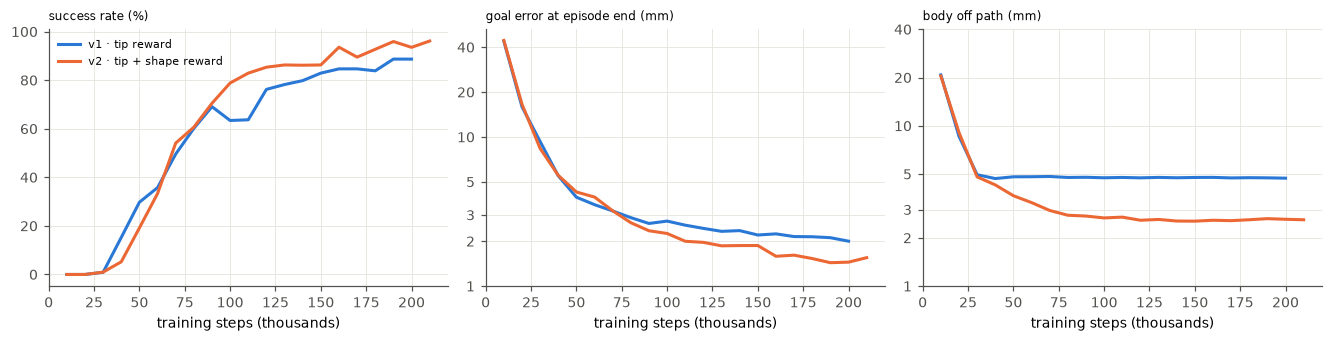

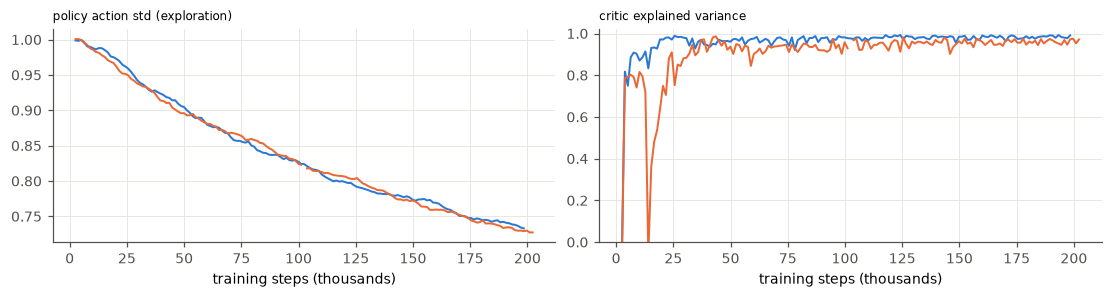

In [17]:
def load_run(run):
    files = sorted(glob.glob(f'{RES}/{run}/monitor_*.monitor.csv'))
    eps = []
    for fn in files:
        with open(fn) as f:
            next(f); rows = list(csv.DictReader(f))
        n = 0
        for r in rows:
            n += int(r['l'])
            eps.append(dict(step=n * len(files), success=r['success'] == 'True', goal=float(r['goal_err_mm']),
                            shape=float(r['shape_err_mm'])))
    return eps

def binned(eps, key, agg, width=10_000):
    edges = np.arange(0, max(e['step'] for e in eps) + width, width)
    out = [(b / 1000, agg([e[key] for e in eps if a < e['step'] <= b])) for a, b in zip(edges[:-1], edges[1:])
           if sum(a < e['step'] <= b for e in eps) >= 10]
    return np.array(out).T

runs = {'v1 · tip reward': ('ppo_p44_server_v1', V1), 'v2 · tip + shape reward': ('ppo_p44_server_v2_shape', V2)}
logs = {k: load_run(r) for k, (r, _) in runs.items()}
fig, axs = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
for ax, (key, title, agg) in zip(axs, [('success', 'success rate (%)', lambda v: 100 * np.mean(v)),
                                       ('goal', 'goal error at episode end (mm)', np.mean),
                                       ('shape', 'body off path (mm)', np.mean)]):
    for k, (r, col) in runs.items():
        x, y = binned(logs[k], key, agg); ax.plot(x, y, color=col, label=k)
    ax.set_title(title, fontsize=8, loc='left'); ax.set_xlabel('training steps (thousands)')
    if key != 'success':
        ax.set_yscale('log'); t = [1, 2, 3, 5, 10, 20, 40]; ax.set_yticks(t); ax.set_yticklabels(t); ax.minorticks_off()
axs[0].legend(frameon=False, fontsize=7); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(10, 2.6), constrained_layout=True)
for k, (r, col) in runs.items():
    rows = [x for f in sorted(glob.glob(f'{RES}/{r}/progress*.csv'), key=lambda f: ('upto' not in f, f)) for x in csv.DictReader(open(f))]
    st = np.array([float(x['time/total_timesteps']) for x in rows]) / 1000
    for ax, key in zip(axs, ['train/std', 'train/explained_variance']):
        ax.plot(st, [float(x[key]) if x.get(key) else np.nan for x in rows], color=col, lw=1.3, label=k)
axs[0].set_title('policy action std (exploration)', fontsize=8, loc='left'); axs[1].set_title('critic explained variance', fontsize=8, loc='left')
axs[1].set_ylim(0, 1.02)
for a in axs: a.set_xlabel('training steps (thousands)')
plt.show()

**Reading the curves.** Both runs escape the wrong branch within about 40k steps: goal error falls from
about 45 mm to under 10 mm. v1's body stays about 4.7 mm off the path for the whole run, because nothing
in its reward refers to the body. v2 halves that and also reaches the goal more accurately: a body on
the path keeps the tip where the goal is reachable. Exploration noise (action std) shrinks smoothly, and
the critic explains about 97 % of the return variance. Both are signs of healthy PPO training.

## 8. Results

In [18]:
def summary(fn):
    z = np.load(fn); n = int(z['n'])
    g = np.array([float(z[f'goal_err_{i}']) for i in range(n)])
    dev = np.array([np.min(np.linalg.norm(z[f'rod_{i}'][:, None] - z['path'][None], axis=2), 1).mean() for i in range(n)])
    return g, dev
print(f'{"policy":<22}{"deterministic goal err":>24}{"test success (n=30)":>22}{"test goal err median [p90]":>30}{"body off path":>16}')
for name, det, ev in [('v1 · tip reward', 'v1_190k_det', 'eval30_v1'), ('v2 · tip + shape', 'v2_final_det', 'eval30_v2')]:
    gd, _ = summary(f'{RES}/rollouts/{det}.npz'); g, dev = summary(f'{RES}/rollouts/{ev}.npz')
    print(f'{name:<22}{gd[0]:21.2f} mm{100 * np.mean(g <= 3):20.0f} %{np.median(g):19.2f} [{np.percentile(g, 90):.2f}] mm{dev.mean():13.2f} mm')
print(f'{"nominal schedule":<22}{float(np.load(f"{RES}/rollouts/unity_baseline.npz")["goal_err_0"]):21.2f} mm{0:20.0f} %')
print('\ntest = 30 new episodes per policy with sampled actions (seed 7), same anatomy; success = goal error <= 3 mm')

policy                  deterministic goal err   test success (n=30)    test goal err median [p90]   body off path
v1 · tip reward                        1.21 mm                  90 %               1.79 [2.97] mm         4.64 mm
v2 · tip + shape                       0.67 mm                  97 %               1.36 [2.62] mm         2.58 mm
nominal schedule                      45.35 mm                   0 %

test = 30 new episodes per policy with sampled actions (seed 7), same anatomy; success = goal error <= 3 mm


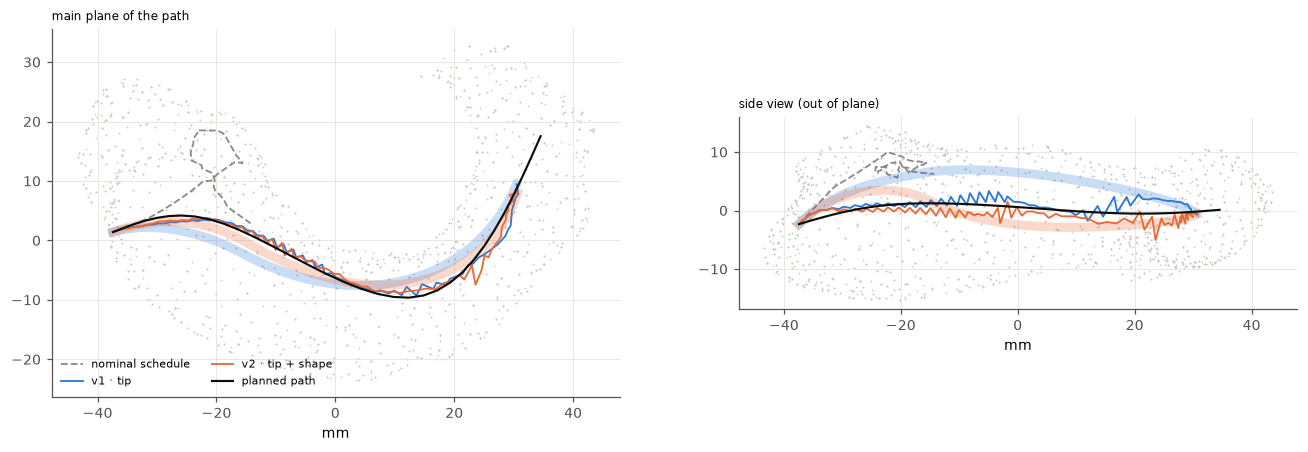

thin: tip path per RL step; wide bands: final robot body (deterministic policies)


In [19]:
c = path.mean(0); _, _, Vt = np.linalg.svd(path - c); P = lambda x: (x - c) @ Vt.T
wall_pts = tris.reshape(-1, 3)[::3]
near = wall_pts[np.min(np.linalg.norm(wall_pts[:, None] - path[None, ::3], axis=2), 1) < 25]
fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True, gridspec_kw={'width_ratios': [1.25, 1]})
for ax, (i, j, title) in zip(axs, [(0, 1, 'main plane of the path'), (0, 2, 'side view (out of plane)')]):
    q = P(near); ax.scatter(q[:, i], q[:, j], s=1.2, color=WALL, lw=0)
    for f, col, lab in [('unity_baseline', BASE, 'nominal schedule'), ('unity_v1', V1, 'v1 · tip'), ('unity_v2', V2, 'v2 · tip + shape')]:
        z = np.load(f'{RES}/rollouts/{f}.npz'); tip = P(z['rods_0'][:, -1]); rod = P(z['rods_0'][-1])
        ax.plot(tip[:, i], tip[:, j], color=col, lw=1.2, ls='--' if 'baseline' in f else '-', label=lab)
        if 'baseline' not in f:
            ax.plot(rod[:, i], rod[:, j], color=col, lw=6, alpha=0.25)
    q = P(path); ax.plot(q[:, i], q[:, j], color=INK, lw=1.4, label='planned path')
    ax.set_aspect('equal'); ax.set_title(title, fontsize=8, loc='left'); ax.set_xlabel('mm')
axs[0].legend(frameon=False, fontsize=7, loc='lower left', ncol=2); plt.show()
print('thin: tip path per RL step; wide bands: final robot body (deterministic policies)')

| | Nominal schedule | PPO v1 (tip) | PPO v2 (tip + shape) |
|---|---|---|---|
| Deterministic goal error | 45.4 mm (wrong branch) | 1.2 mm | **0.7 mm** |
| Success, 30 test episodes | 0 % | 90 % | **97 %** |
| Body off path | 8.3 mm | 4.6 mm | **2.5 mm** |

Results repeat exactly on one platform, not across platforms: the deterministic v2 rollout ends 0.67 mm
from the goal on Linux x86-64 (where these numbers were produced) and 0.74 mm on macOS arm64, because
the contact solver's floating-point results differ slightly.

## 9. Interactive demo (Gradio)

`sofa_rl/app.py` has three tabs: **Replay** (3D replay of the recorded insertions with a step slider),
**Results**, and **Live SOFA** (runs a new simulation with a chosen policy, action mode and seed; shown only
where SOFA is installed).

In [20]:
LAUNCH_APP = False
if LAUNCH_APP:
    import sys; sys.path.insert(0, ROOT)
    from app import demo
    demo.launch(inline=True, height=900)          # or: python sofa_rl/app.py   (add --share for a public link)

## 10. Takeaways and limitations

* **Residual RL** on a physically fitted schedule makes the problem learnable in about 10⁵ simulator steps.
* **Reward design matters most.** A body-to-path term halved the body deviation and improved the task metric.
* **Simulator settings are part of the task** (contact-solver tolerance), and long simulation-in-the-loop
  training needs **resource management** (worker respawning).

Limitations: one anatomy for training and testing, rigid wall, no sensor noise or domain randomisation,
30 test episodes per policy. Next steps: train on many patients and test on held-out ones; randomise wall
stiffness, friction, actuator gain and registration; add a history-dependent (poroviscoelastic) wall;
compare against non-learned baselines.